# Introduccion
El caso seleccionado trata del negocio de alquileres temporarios de Airbnb. La pregunta que se plantea resolver es que oportunidades de inversion hay presentes y que recomendaciones se pueden realizar para los inversores.
Los puntos que siento que seran mas relevantes son:
- Cantidad optima de habitaciones segun la zona
- Temporadas ideales para alquilar
- Inversion sobre costo del M2 para identificar la inversion mas ideal

Ademas se busca describir el mercado de Airbnb a traves de los datos, por lo que presentare la estadia promedio en dias, las zonas que se suelen alquilar y ofreces (con el supuesto de que son las zonas turisticas)
Tambien comparar Airbnb con otras alternativas de inversion, para esto utilizare el S&P para demostrar cual es el retorno anual promedio entre los dos y tomare en cuenta tambien cuanto aumenta el valor de la propiedad.
La otra alternativa de inversion es comprar un hotel, podria investigar sobre costos y rendimientos de estos

Estos son los puntos brindados por el TP 
- ¿Cuáles son las características más rentables de las propiedades de Airbnb?
- ¿Qué tipo de propiedades y en qué ubicaciones presentan mejores oportunidades de inversión?
- ¿Qué relación existe entre los precios de las propiedades y sus valoraciones?
- ¿Qué recomendaciones de inversión podemos realizar basándonos en los datos?

En base a estos se puede sumar:
- Cual es el tipo de propiedad/caracteristicas ideal en base a zona

se podria hcer na calculcadora para que te ayude a conseguir un precio estimado que podrias poner tu alquiler

# Etapa 1

## Exploración inicial de los Datos
Importamos los archivos csv a traves de pandas y realizamos una exploracion inicial de los datos para identificar y entender su composicion
<p> Comenzamos por la importacion de las librerias Pandas y Maplotlib <p>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.0f}'.format)

## Importacion de la información
Utilizamos Pandas para leer los archivos csv y de esta manera importarlos al espacio de trabajo. Adicionalmente visualizamos las columnas de los datasets junto a las primeras 10 lineas y el Dtype por columna.
Para facilitar su visualización y la comprension del archivo, dividire cada etapa en 3 por cada dataframe. Le doy un valor unico a la ubicacion del archivo de manera que pueda llamar y/o cambiar a esta ubicacion de manera centralizada.

In [2]:
#folder = r"C:\Users\Fausto\Downloads\\"
folder = r"C:\Users\fausto\Desktop\Digital House\Presentaciones y archivos\5 - Desafio Profesional Data Analyst Etapa 1\AirBnB\\"
calendar = pd.read_csv(folder+'calendar.csv')
listings = pd.read_csv(folder+'listings.csv')
reviews = pd.read_csv(folder+'reviews.csv')

C:\Users\fausto\AppData\Local\Temp\ipykernel_14176\3085628440.py:4: DtypeWarning: Columns (61,62,95) have mixed types. Specify dtype option on import or set low_memory=False.
  listings = pd.read_csv(folder+'listings.csv')


## 1. Datasets

### a. Calendar
Calendario de todo el año con las propiedades en cada fecha junto a su disponibilidad y precio distribuido a traves de las fechas.

#### Carga del dataset

In [3]:
def descripcion(df):
  display(df.shape)
  display(df.head())
  display(df.info())

descripcion(calendar)

(8661286, 7)

,listing_id,date,available,price,adjusted_price,minimum_nights,maximum_nights
0,50778,2020-04-26,f,"$2,655.00","$2,655.00",5,1125
1,133654,2020-04-27,t,"$1,150.00","$1,150.00",4,1125
2,133654,2020-04-28,t,"$1,150.00","$1,150.00",4,1125
3,133654,2020-04-29,t,"$1,150.00","$1,150.00",4,1125
4,133654,2020-04-30,t,"$1,150.00","$1,150.00",4,1125


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8661286 entries, 0 to 8661285
Data columns (total 7 columns):
 #   Column          Dtype  
---  ------          -----  
 0   listing_id      int64  
 1   date            object 
 2   available       object 
 3   price           object 
 4   adjusted_price  object 
 5   minimum_nights  float64
 6   maximum_nights  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 462.6+ MB


None

In [4]:
#Convierto las columnas de dinero que deberian ser numericos a float para poder utilizar correctamente la funcion describe y las columnas de fecha a datetime
def descripcion_ajustada(df, numericas,fechas):
  for columna in numericas:
    if df[columna].dtype == 'object':
      df[columna] = (
            df[columna]
            .str.replace('$', '', regex=False)
            .str.replace(',','', regex=False)
            .astype(float)
          )
  for columna in fechas:
    df[columna] = pd.to_datetime(df[columna])
  display(df.describe(include= 'all'))
descripcion_ajustada(calendar, calendar[['price', 'adjusted_price']], calendar[['date']])

,listing_id,date,available,price,adjusted_price,minimum_nights,maximum_nights
count,8661286,8661286,8661286,8661286,8661286,8661181,8661181
unique,NaN,NaN,2,NaN,NaN,NaN,NaN
top,NaN,NaN,t,NaN,NaN,NaN,NaN
freq,NaN,NaN,5031220,NaN,NaN,NaN,NaN
mean,26685457,2020-10-25 04:13:56.891520512,NaN,3939,3934,6,769
min,11508,2020-04-26 00:00:00,NaN,19,19,1,1
25%,17656805,2020-07-26 00:00:00,NaN,1350,1340,1,90
50%,30008780,2020-10-25 00:00:00,NaN,2000,1999,3,1125
75%,37362406,2021-01-24 00:00:00,NaN,3296,3253,4,1125
max,43286057,2021-04-26 00:00:00,NaN,6637914,6637914,1125,99999


In [5]:
print(calendar['date'].min())
print(calendar['date'].max())

2020-04-26 00:00:00
2021-04-26 00:00:00


A primera vista se puede observar que:
1. Los datos de precios van a verse representados como una curva con un sesgo extremo a la derecha dado que la media es mayor a la mediana y el valor maximo es extremadamente mayor al tercer cuartil y la media. Esto significara que <br>habra eliminar los outliers superiores para realizar un correcto analisis.
2. Los valores de price y adjusted_price son casi identicos, tienen unas diferencias muy bajas
3. Que existe por lo menos una fila incorrecta en la columna de minium_nights debido a que Airbnb es un negocio de alquiler temporal y existe por lo menos un caso con un minimo de 1125 noches para alquilar
4. El calendario corresponde a un año, comenzando el 26 de abril 2020 al 26 de abril 2021. Por fines didacticos se decidio tomar el caso como un hipotetico donde la cuarentena y la pandemia no sucedieron ya que de no ser asi, el caso de estudio no seria un caso de uso ideal para explorar el normal funcionamiento del negocio

#### Limpieza preliminar
Identificamos la cantidad de valores nulos por columna y que % representa del total para identificar las columnas no utilizadas.

In [6]:
#Previamente eliminamos todas las columnas que no contienen ningun valor
def null_count(df): 
  df = df.dropna(
      axis=1,
      how='all');
  null_count = df.isnull().sum()
  null_df = (
    pd.DataFrame
    ({'null_count': null_count,
      'total_population': len(df), 
      'null_percentage':((null_count/len(df))*100).round(2)})
  )
  display(null_df)

null_count(calendar)

,null_count,total_population,null_percentage
listing_id,0,8661286,0
date,0,8661286,0
available,0,8661286,0
price,0,8661286,0
adjusted_price,0,8661286,0
minimum_nights,105,8661286,0
maximum_nights,105,8661286,0


Debido a que las lineas con valores nulos corresponde al limite de noches maximas y minimas se tomo la decision de reemplazar los valores por 0 y 99999 ya que los nulos indicarian (USAR OTRAS PALABRAS, BOMBON!!!) que no indicaron limites a estos.

In [7]:
#Reemplazo los valores nulos por 0 y 99999 en las columnas minimum_nights y maximum_nights respectivamente
calendar['minimum_nights'] = calendar['minimum_nights'].fillna(0)
calendar['maximum_nights'] = calendar['maximum_nights'].fillna(99999)
null_count(calendar);

,null_count,total_population,null_percentage
listing_id,0,8661286,0
date,0,8661286,0
available,0,8661286,0
price,0,8661286,0
adjusted_price,0,8661286,0
minimum_nights,0,8661286,0
maximum_nights,0,8661286,0


Corregimos el datatype de la columna:
available es una columna del tipo true('t') o false('f') por lo que para eficientizar su uso lo transformar a un tipo de dato booleano

In [8]:
def boolean_columns(df,columns):
  for column in columns:
    df[column] = df[column].map({'t': True, 'f': False}).astype(bool)
  display(df[columns].info())
boolean_columns(calendar, ['available'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8661286 entries, 0 to 8661285
Data columns (total 1 columns):
 #   Column     Dtype
---  ------     -----
 0   available  bool 
dtypes: bool(1)
memory usage: 8.3 MB


None

#### Exploracion preliminar

Comenzamos por la columna price dado que supone ser la esencial para el analisis de este dataframe. Exploro la distribucion de los precios utilizando un boxplot para identificar si existen anomalias y un scatterplot para ver su distribucion en el tiempo

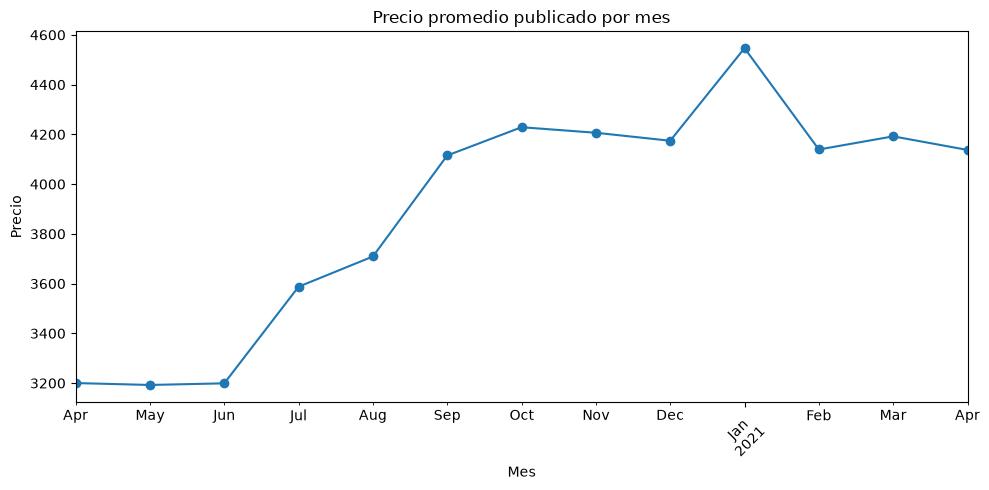

In [9]:
precio_mensual = calendar.groupby(calendar['date'].dt.to_period('M'))['price'].mean()

plt.figure(figsize=(10,5))
precio_mensual.plot(kind='line', marker='o')
plt.title("Precio promedio publicado por mes")
plt.ylabel("Precio")
plt.xlabel("Mes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ver si dejo un grafico como este pero con el porcentaje de true y false de available como valor

A primer vista se puede inducir que el precio de las publicaciones aumenta aparejado con la temperatura

Text(0.5, 0, 'Price')

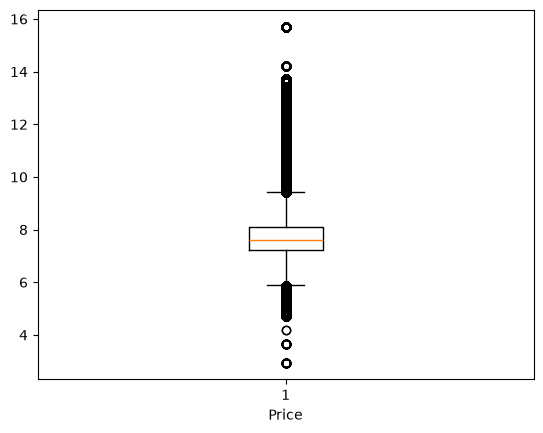

In [10]:
month = calendar['date'].dt.to_period('M').astype(str) #Convierto a mes la columna date para poder graficar los precios a traves del año
plt.boxplot(x= np.log(calendar['price'])) #Utilizo un boxplot para identificar outliers
plt.xlabel('Price')

Estos cuartiles me dan la pauta de que los valores podrian ser separados por categorias de nivel economico. Por estas razones voy a calcular el limite inferior y superior del rango intercuartilico en pos de obtener los rangos para las categorias de nivel economico. Para realizar esto agrupo a las publicaciones por la media de su precio en todo el año y realizo el calculo con una escala logaritmica dado que hay puntas muy extremas que sin utilizar esta escala no me permitirian obtener el rango inferior.

In [11]:
# Detección de outliers en precio por listing (log-IQR, por sesgo a la derecha)
precio_por_listing = calendar.groupby('listing_id')['price'].median()
log_precio = np.log1p(precio_por_listing)

Q1_log, Q3_log = log_precio.quantile([0.25, 0.75])
IQR_log = Q3_log - Q1_log
lim_inf = np.expm1(Q1_log - 1.5 * IQR_log)
lim_sup = np.expm1(Q3_log + 1.5 * IQR_log)

print(f"Límites (log-IQR): [{lim_inf:.0f}, {lim_sup:.0f}]")

# 1. Identificamos los outliers y documentos sus limites
outliers_precio = precio_por_listing[(precio_por_listing > lim_sup) | (precio_por_listing < lim_inf)]
print(f"Propiedades eliminadas por outlier de precio: {len(outliers_precio)} ({len(outliers_precio)/len(precio_por_listing)*100:.1f}%)")

#creamos una serie limpia donde no se encuentran los outliers
precio_por_listing_limpio = precio_por_listing[
    (precio_por_listing >= lim_inf) & (precio_por_listing <= lim_sup)
]

# 2. Categorizamos la serie limpia de outliers en categorias de precio
categoria_precio = pd.cut(
    precio_por_listing_limpio,
    bins=[0, precio_por_listing_limpio.quantile(0.33), precio_por_listing_limpio.quantile(0.66), np.inf],
    labels=['económico', 'medio', 'premium']
)

print(categoria_precio.value_counts())

Límites (log-IQR): [379, 12188]
Propiedades eliminadas por outlier de precio: 662 (2.8%)
price
medio        8264
económico    7667
premium      7136
Name: count, dtype: int64


En base a lo analizado voy a crear una tabla

In [12]:
#Creo un dataframe por medio de la funcion agg() para asi obtener un dataset con los listings agrupando con los valores utiles ya calculados
resumen_calendario = calendar.groupby('listing_id').agg(
    precio_promedio=('price', 'mean'),
    precio_mediano=('price', 'median'),
    dias_registrados=('date', 'count'),
    dias_disponibles=('available', 'sum'),
    tasa_disponibilidad=('available', 'mean'),
    min_nights_tipico=('minimum_nights', 'median'),
).reset_index()

resumen_calendario['tasa_disponibilidad'] = (resumen_calendario['tasa_disponibilidad'] * 100).round(2)

# Sacamos los outliers de precio que ya identificaste
resumen_calendario = resumen_calendario[resumen_calendario['listing_id'].isin(precio_por_listing_limpio.index)]

# Le pegamos la categoría de precio
resumen_calendario = resumen_calendario.merge(
    categoria_precio.rename('categoria_precio'),
    left_on='listing_id', right_index=True
)

print(resumen_calendario.shape)
resumen_calendario.head()

(23067, 8)


,listing_id,precio_promedio,precio_mediano,dias_registrados,dias_disponibles,tasa_disponibilidad,min_nights_tipico,categoria_precio
0,11508,3983,3983,365,365,100,2,premium
1,12463,1792,1792,365,365,100,1,medio
2,13095,2987,2987,365,365,100,1,premium
3,13096,2987,2987,365,365,100,1,premium
4,13097,2987,2987,365,365,100,1,premium


### b. Listings
Listado de propiedades con toda la informacion disponible sobre estas 

#### Carga del dataset

In [13]:
descripcion(listings)

(23729, 106)

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,access,interaction,house_rules,thumbnail_url,medium_url,picture_url,xl_picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,street,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,city,state,zipcode,market,smart_location,country_code,country,latitude,longitude,is_location_exact,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities,square_feet,price,weekly_price,monthly_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11508,https://www.airbnb.com/rooms/11508,20200426042522,2020-04-26,Amazing Luxurious Apt-Palermo Soho,NaN,LUXURIOUS NEW APT: 1 BDRM- POOL/ GYM/ SPA/ 24-...,LUXURIOUS NEW APT: 1 BDRM- POOL/ GYM/ SPA/ 24-...,none,AREA: PALERMO SOHO Minutes walking distance fr...,NaN,All major bus lines are nearby. Stop: Plaza It...,Outdoor pool and outdoor area on first floor F...,NaN,"During your stay in the apt, you must follow t...",NaN,NaN,https://a0.muscache.com/im/pictures/19357696/b...,NaN,42762,https://www.airbnb.com/users/show/42762,Candela,2009-10-01,"New York, New York, United States",-,within a few hours,100%,100%,t,https://a0.muscache.com/im/users/42762/profile...,https://a0.muscache.com/im/users/42762/profile...,Palermo,1,1,"['email', 'phone', 'reviews', 'kba']",t,t,"Buenos Aires, Capital Federal, Argentina",Palermo,Palermo,NaN,Buenos Aires,Capital Federal,NaN,Buenos Aires,"Buenos Aires, Argentina",AR,Argentina,-35,-58,t,Condominium,Entire home/apt,2,1,1,1,Real Bed,"{TV,""Cable TV"",Internet,Wifi,""Air conditioning...",NaN,"$3,983.00","$39,828.00","$82,975.00",$0.00,"$3,319.00",1,$0.00,2,1125,2,2,1125,1125,2,1125,2 months ago,t,30,60,90,365,2020-04-26,26,4,2012-07-02,2019-11-28,95,10,10,10,10,10,10,f,NaN,NaN,f,f,strict_14_with_grace_period,f,f,1,1,0,0,0
1,12463,https://www.airbnb.com/rooms/12463,20200426042522,2020-04-26,Room in Recoleta - awesome location,My apartment is centrally located in Recoleta ...,This is a very comfortable pull-out sofa in th...,My apartment is centrally located in Recoleta ...,none,It's near the school of medicine so the street...,NaN,Just a block from the Facultad de Medicina sub...,"Wi-Fi, kitchen, TV, Playstation 3",I work out of my apartment so I am around duri...,"Nothing formal, but no smoking and no guests w...",NaN,NaN,https://a0.muscache.com/im/pictures/11680256/5...,NaN,48799,https://www.airbnb.com/users/show/48799,Matt,2009-10-28,"Danbury, Connecticut, United States",I'm an expatriate from the USA who has been li...,within a few hours,100%,NaN,f,https://a0.muscache.com/im/pictures/user/2e5c6...,https://a0.muscache.com/im/pictures/user/2e5c6...,Recoleta,1,1,"['email', 'phone', 'reviews', 'jumio', 'govern...",t,t,"Buenos Aires, Capital Federal, Argentina",Recoleta,Recoleta,NaN,Buenos Aires,C

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23729 entries, 0 to 23728
Columns: 106 entries, id to reviews_per_month
dtypes: float64(23), int64(21), object(62)
memory usage: 19.2+ MB


None

In [14]:
descripcion_ajustada(listings, ['price','weekly_price','monthly_price','security_deposit','cleaning_fee','extra_people'],['last_scraped', 'host_since', 'calendar_last_scraped', 'first_review', 'last_review'])
boolean_columns(listings, ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'is_location_exact', 'instant_bookable', 'require_guest_profile_picture', 'require_guest_phone_verification'])

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,access,interaction,house_rules,thumbnail_url,medium_url,picture_url,xl_picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,street,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,city,state,zipcode,market,smart_location,country_code,country,latitude,longitude,is_location_exact,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities,square_feet,price,weekly_price,monthly_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,23729,23729,23729,23729,23719,22345,16535,22928,23729,16064,7722,14508,10204,13905,10651,0,0,23729,0,23729,23729,23726,23726,23626,13729,16843,16843,18530,23726,23726,23726,20870,23726,23726,23726,23726,23726,23729,23729,23729,0,23142,23546,18542,23708,23729,23729,23729,23729,23729,23729,23729,23729,23729,23667,23686,23562,23729,23729,383,23729,2541,2578,15534,16944,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,23729,17222,17222,16839,16822,16822,16822,16821,16822,16820,23729,0,7,23729,23729,23729,23729,23729,23729,23729,23729,23729,17222
unique,NaN,23729,NaN,NaN,22918,20951,15536,22139,1,14240,6713,12993,9115,12075,9152,NaN,NaN,23145,NaN,NaN,15536,3885,NaN,1025,7738,4,47,82,2,15492,15492,115,NaN,NaN,339,2,2,1108,48,48,NaN,852,75,827,6,852,2,2,NaN,NaN,2,34,4,NaN,NaN,NaN,NaN,5,22533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,6,2,1,5,2,2,NaN,NaN,NaN,NaN,NaN
top,NaN,https://www.airbnb.com/rooms/11508,NaN,NaN,Departamento en Recoleta,.,Restaurantes + Bares + Discotecas + Arte + Gen...,Estamos cerca de las principales estaciones de...,none,El barrio es mágico. Cada vez más turistas eli...,"En estadías MAYORES a un mes, es necesario ab...",Colectivos y Subte disponibles a pocos pasos. ...,El edificio cuenta con una terraza en el piso ...,Si,Es necesario firmar un contrato de locación al...,NaN,NaN,https://a0.muscache.com/im/pictures/1fb6a93c-9...,NaN,NaN,https://www.airbnb.com/users/show/7786587,Maria,NaN,"Buenos Aires, Buenos Aires, Argentina",Argentina,within an hour,100%,100%,f,https://a0.muscache.com/im/users/7786587/profi...,https://a0.muscache.com/im/users/7786587/profi...,Palermo,NaN,NaN,"['email', 'phone']",t,f,"Palermo, Buenos Aires, Argentina",Palermo,Palermo,NaN,Buenos Aires,Buenos Aires,C1425,Buenos Aires,"Buenos Aires, Argentina",AR,Argentina,NaN,NaN,t,Apartment,Entire home/apt,NaN,NaN,NaN,NaN,Real Bed,{},NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 months ago,t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,NaN,"{""Florida State"","" Sarasota County"","" FL""}",t,f,flexible,f,f,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,NaN,Na

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23729 entries, 0 to 23728
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   host_is_superhost                 23729 non-null  bool 
 1   host_has_profile_pic              23729 non-null  bool 
 2   host_identity_verified            23729 non-null  bool 
 3   is_location_exact                 23729 non-null  bool 
 4   instant_bookable                  23729 non-null  bool 
 5   require_guest_profile_picture     23729 non-null  bool 
 6   require_guest_phone_verification  23729 non-null  bool 
dtypes: bool(7)
memory usage: 162.3 KB


None

A primera vista podemos identificar ciertas cosas:
1. experiences_offered tiene un solo valor el cual es none, seria adecuado eliminarla. has_availability tambien, es t y requires_license y is_business_travel_ready que es f
2. thumbnail_url, medium_url, xl_picture_url, neighbourhood_group_cleansed y license no contienen valores, seria adecuado eliminarla
3. host_has_profile_pic, host_identity_verified, is_location_exact, instant_bookable, require_guest_profile_picture y require_guest_phone_verification son columnas de t (true) y f (false), podrian ser convertidas a booleans

Usar value_counts para dejar bien los nombres de los barrios y etc

Comparamos la cantidad de IDs unicos en la tabla listings con los IDs unicos de la tabla calendar para confirmar si estos coinciden y estamos viendo efectivamente las mismas publicaciones

In [15]:
display(calendar["listing_id"].nunique())
display(listings["id"].nunique())
display(len(set(calendar["listing_id"]) - set(listings["id"])))

23729

23729

0

#### Limpieza preliminar
Identificamos la cantidad de valores nulos por columna y que % representa del total para identificar las columnas no utilizadas.

In [16]:
null_count(listings)

,null_count,total_population,null_percentage
id,0,23729,0
listing_url,0,23729,0
scrape_id,0,23729,0
last_scraped,0,23729,0
name,10,23729,0
summary,1384,23729,6
space,7194,23729,30
description,801,23729,3
experiences_offered,0,23729,0
neighborhood_overview,7665,23729,32


#### Exploracion preliminar

In [17]:
#Exploramos los casos superiores a 400000 para ver a que se deben los precios altos.
display(listings[listings['price']>400000])

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,access,interaction,house_rules,thumbnail_url,medium_url,picture_url,xl_picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,street,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,city,state,zipcode,market,smart_location,country_code,country,latitude,longitude,is_location_exact,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities,square_feet,price,weekly_price,monthly_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
15110,33770387,https://www.airbnb.com/rooms/33770387,20200426042522,2020-04-27,Alojate en histórico barrio del Abasto y disfr...,La casa es muy tranquila y espaciosa. Con much...,Para sentirte como en tu casa. Disfrutar al ai...,La casa es muy tranquila y espaciosa. Con much...,none,"Barrio histórico. Tango, música y actividades ...",Para estancias de 1 o 2 noches se cobra $150 d...,A metros de líneas de subte B y D. Gran varied...,Cocina equipada y baño completo se comparten c...,Vivo en esta casa y trabajo varias horas acá t...,- Respetar el descanso nocturno durante los dí...,NaN,NaN,https://a0.muscache.com/im/pictures/049186ee-0...,NaN,219952939,https://www.airbnb.com/users/show/219952939,Marisa,2018-10-10,"Buenos Aires, Buenos Aires, Argentina",Me gusta viajar y compartir experiencias. Amo ...,within an hour,100%,100%,False,https://a0.muscache.com/im/pictures/user/d7205...,https://a0.muscache.com/im/pictures/user/d7205...,Balvanera,1,1,"['email', 'phone']",True,False,"Balvanera, Buenos Aires, Argentina",Balvanera,Balvanera,NaN,Balvanera,Buenos Aires,C1191,Buenos Aires,"Balvanera, Argentina",AR,Argentina,-35,-58,True,House,Private room,1,2,1,1,Real Bed,"{Wifi,""Air conditioning"",Kitchen,""Paid parking...",NaN,466511,NaN,NaN,0,0,1,0,2,10,2,2,10,10,2,10,2 months ago,t,30,60,90,90,2020-04-27,4,4,2019-04-29,2019-08-23,100,10,9,10,10,10,9,f,NaN,NaN,True,f,flexible,False,False,1,0,1,0,0
15252,33896380,https://www.airbnb.com/rooms/33896380,20200426042522,2020-04-27,"Departamento Luminoso, ideal Universitario",Cuenta con 2 ambientes al frente con cómodo ba...,el Departamento cuenta con exelente ubicación....,Cuenta con 2 ambientes al frente con cómodo ba...,none,"A pocas cuadras de amplios parques, muy cerca ...",NaN,Dispone de colectivos y subtes en el radio de...,NaN,Estoy Disponible para visitarlo cuando gusten....,NaN,NaN,NaN,https://a0.muscache.com/im/pictures/f866adb1-5...,NaN,26761129,https://www.airbnb.com/users/show/26761129,Maria,2015-01-26,AR,NaN,a few days or more,0%,0%,False,https://a0.muscache.com/im/pictures/user/bf78d...,https://a0.muscache.com/im/pictures/user/bf78d...,Balvanera,1,1,"['email', 'phone']",True,False,"Balvanera, Buenos Aires, Argentina",Balvanera,Balvanera,NaN,Balvanera,Buenos Aires,C1222,Buenos 

Por medio del listing_url accedi a las 9 publicaciones para comprender a que se deben sus precios. De estas tan solo una contiene un url activo en el cual el precio alto no se puede explicar por el producto ofrecido o por un error de tipeo. Esto se debe a que es una publicacion que se podria considerar categoria media y el precio no se asemeja de ninguna forma al obtenido en el dataset, ya sea por conversion, error de tipo, etc. Dada esta situacion se decidio continuar con la remocion de los outliers

Creamos una nueva tabla

In [18]:
listings_full = listings[['id','amenities',
'property_type',
'house_rules',
'host_identity_verified',
'neighbourhood_cleansed',
'room_type',
'accommodates',
'bathrooms',
'bedrooms',
'beds',
'bed_type',
'review_scores_rating']].merge(resumen_calendario, left_on='id', right_on='listing_id')

In [19]:
print(listings_full.shape)
print(listings_full.columns.tolist())

(23067, 21)
['id', 'amenities', 'property_type', 'house_rules', 'host_identity_verified', 'neighbourhood_cleansed', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'bed_type', 'review_scores_rating', 'listing_id', 'precio_promedio', 'precio_mediano', 'dias_registrados', 'dias_disponibles', 'tasa_disponibilidad', 'min_nights_tipico', 'categoria_precio']


RECORDAR CRUZAR 15 AMMENITIES MAS COMUNES CON PRECIO PROMEDIO PARA OBTENER CUALES MEJOR LOS PRECIOS

In [20]:
# Línea 1: limpiar caracteres y separar por comas
amenities_table = listings['amenities'].str.replace('{','',regex=False).str.replace('}','',regex=False).str.replace('"','',regex=False).str.split(',')

# Línea 2: aplicar strip a cada elemento de cada lista, explotar, y contar
amenities_table = amenities_table.apply(lambda lista: [elemento.strip() for elemento in lista])
amenities_table = amenities_table.explode()
conteo_amenities = amenities_table.value_counts()
conteo_amenities.head(9999)

amenities
Wifi                                          23109
Kitchen                                       22375
Essentials                                    22360
Heating                                       21400
Hangers                                       20707
TV                                            19976
Air conditioning                              19708
Laptop friendly workspace                     16811
Elevator                                      16022
Hot water                                     15879
Iron                                          14762
Hair dryer                                    14728
Dishes and silverware                         13468
Washer                                        13233
Refrigerator                                  12305
Shampoo                                       12191
Cooking basics                                11951
Microwave                                     10402
Oven                                          10384
Be

### c. Reviews
Reseñas de usuarios sobre las propiedades alquiladas

In [21]:
descripcion(reviews)

(387099, 6)

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,11508,1615861,2012-07-02,877808,Charlie,Amazing place!\r\n\r\nLocation: short walk to ...
1,11508,3157005,2012-12-26,656077,Shaily,Really enjoyed Candela's recommendations and q...
2,11508,3281011,2013-01-05,2835998,Michiel,Candela and her colleague were very attentive ...
3,11508,6050019,2013-07-28,4600436,Tara,"The apartment was in a beautiful, modern build..."
4,11508,9328455,2013-12-22,3130017,Simon,My stay at Candela's apartment was very enjoya...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 387099 entries, 0 to 387098
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   listing_id     387099 non-null  int64 
 1   id             387099 non-null  int64 
 2   date           387099 non-null  object
 3   reviewer_id    387099 non-null  int64 
 4   reviewer_name  387099 non-null  object
 5   comments       386923 non-null  object
dtypes: int64(3), object(3)
memory usage: 17.7+ MB


None

#### Valores Nulos
Identificamos la cantidad de valores nulos por columna y que % representa del total para identificar las columnas no utilizadas.

In [22]:
null_count(reviews)

,null_count,total_population,null_percentage
listing_id,0,387099,0
id,0,387099,0
date,0,387099,0
reviewer_id,0,387099,0
reviewer_name,0,387099,0
comments,176,387099,0


## Visualizaciones iniciales

In [23]:
for name, df in [('Calendar', calendar), ('Listings', listings), ('Reviews', reviews)]:
    print(f"\n{'='*60}")
    print(f"  {name} - Null Values")
    print(f"{'='*60}\n")
    if name == 'Listings':
        display(df.describe(include=['price', 'adjusted_price']))
    elif name == 'Calendar':
        display(df.describe(include=['price']))  


  Calendar - Null Values



TypeError: data type 'price' not understood

<Axes: xlabel='city,state'>

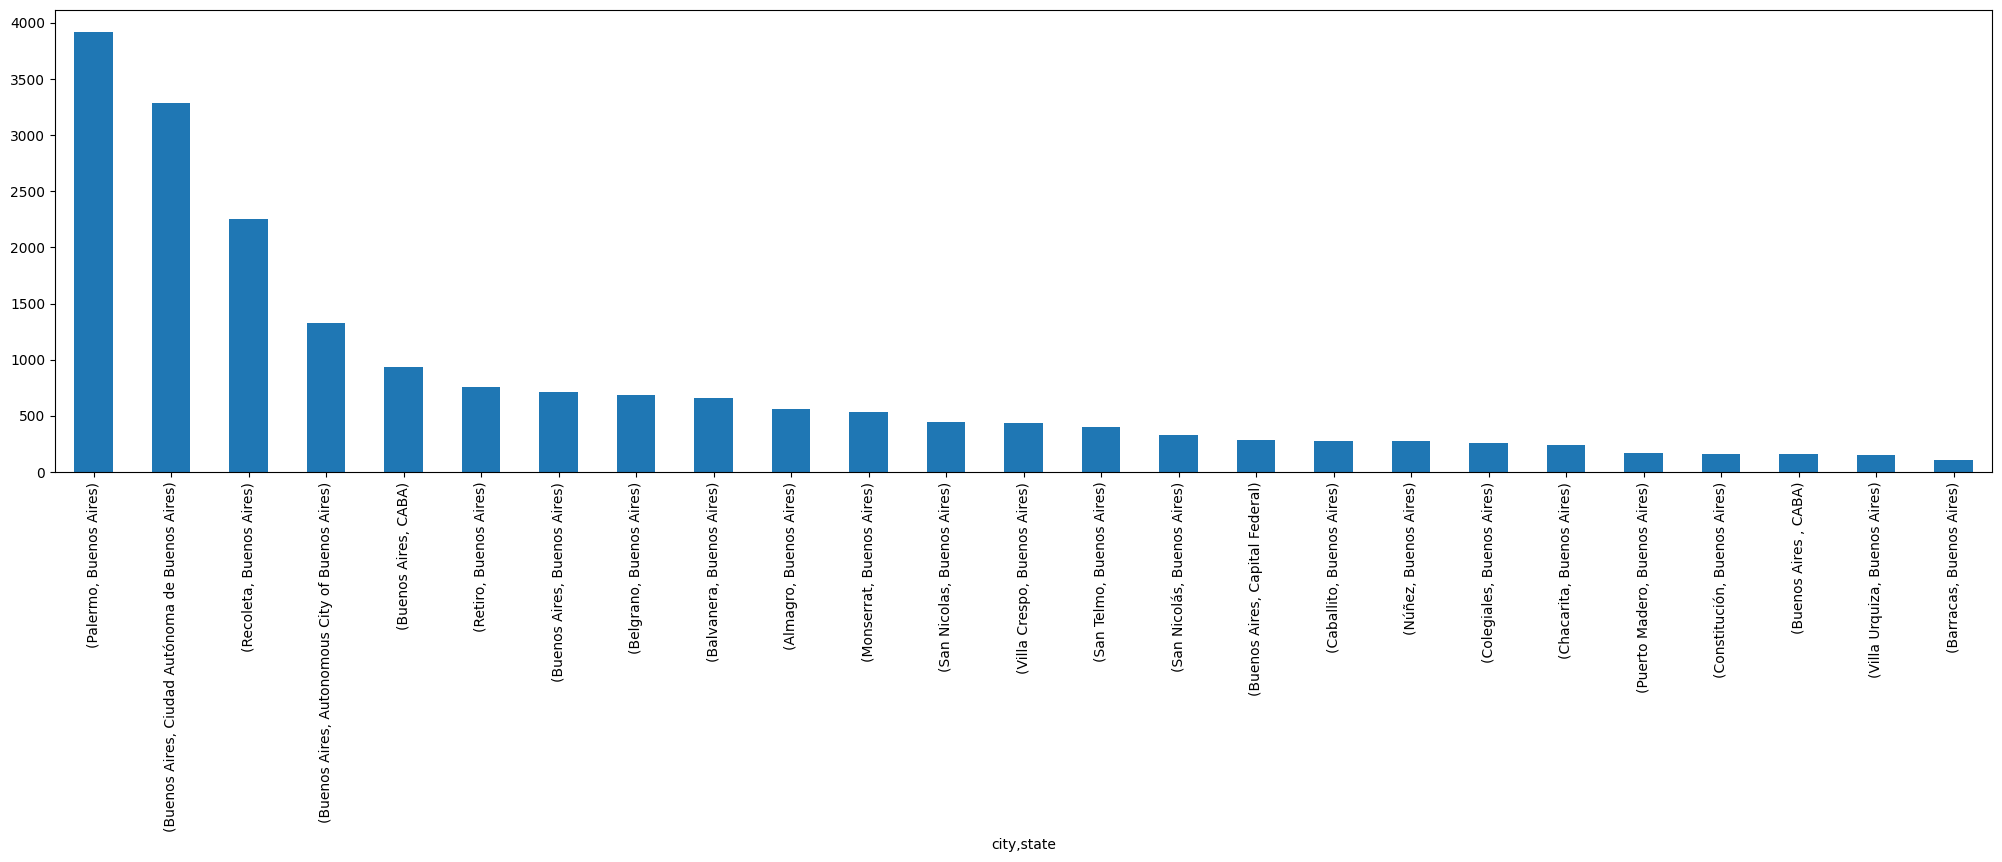

In [ ]:
df = listings[['host_neighbourhood','host_total_listings_count','city','state','price','property_type','room_type']]
df.value_counts(subset=['city','state']).head(25).plot(kind='bar', figsize =(25, 6))